# Efficient LCC Discovery: Mini Demo

This notebook demonstrates `discover_lcc_efficient` from `eff_lcc.py` on synthetic
2D multi-modal data with **4 modalities**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from eff_lcc import discover_lcc_efficient

rng = np.random.default_rng(1029384756)

In [2]:
#generate synthetic multi-modal data
n_modalities = 4
n_cohorts = 10
n_noise = 90
n = n_cohorts + n_noise
true_cohort = np.arange(n_cohorts)

coords_per_modality = []
for k in range(n_modalities):
    center = rng.uniform(-8, 8, size=2)
    cohort_pts = center + rng.normal(scale=0.5, size=(n_cohorts, 2))
    noise_pts = rng.uniform(-10, 10, size=(n_noise, 2))
    coords_per_modality.append(np.vstack([cohort_pts, noise_pts]))

print(f"n = {n} points, {n_modalities} modalities, true LCC size = {n_cohorts}")

n = 100 points, 4 modalities, true LCC size = 10


In [3]:
#pairwise distance matrices
def pairwise_distances(coords: np.ndarray) -> np.ndarray:
    diff = coords[:, None, :] - coords[None, :, :]
    return np.sqrt(np.sum(diff ** 2, axis=-1))

dist_matrices = [pairwise_distances(c) for c in coords_per_modality]

In [4]:
#run LCC discovery
cohorts, noise_set = discover_lcc_efficient(dist_matrices, alpha=0.1, min_cluster_size=3)

print(f"Found {len(cohorts)} LCC:")
for c in cohorts:
    print(f"  size {len(c)}: {c}")
print(f"Noise points: {len(noise_set)}")

detected = set(cohorts[0]) if cohorts else set()
recall = len(detected & set(true_cohort)) / n_cohorts
precision = len(detected & set(true_cohort)) / len(detected) if detected else 0.0
print(f"Recall vs. true LCC: {recall:.2f}, Precision: {precision:.2f}")

Found 1 LCC:
  size 10: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Noise points: 90
Recall vs. true LCC: 1.00, Precision: 1.00


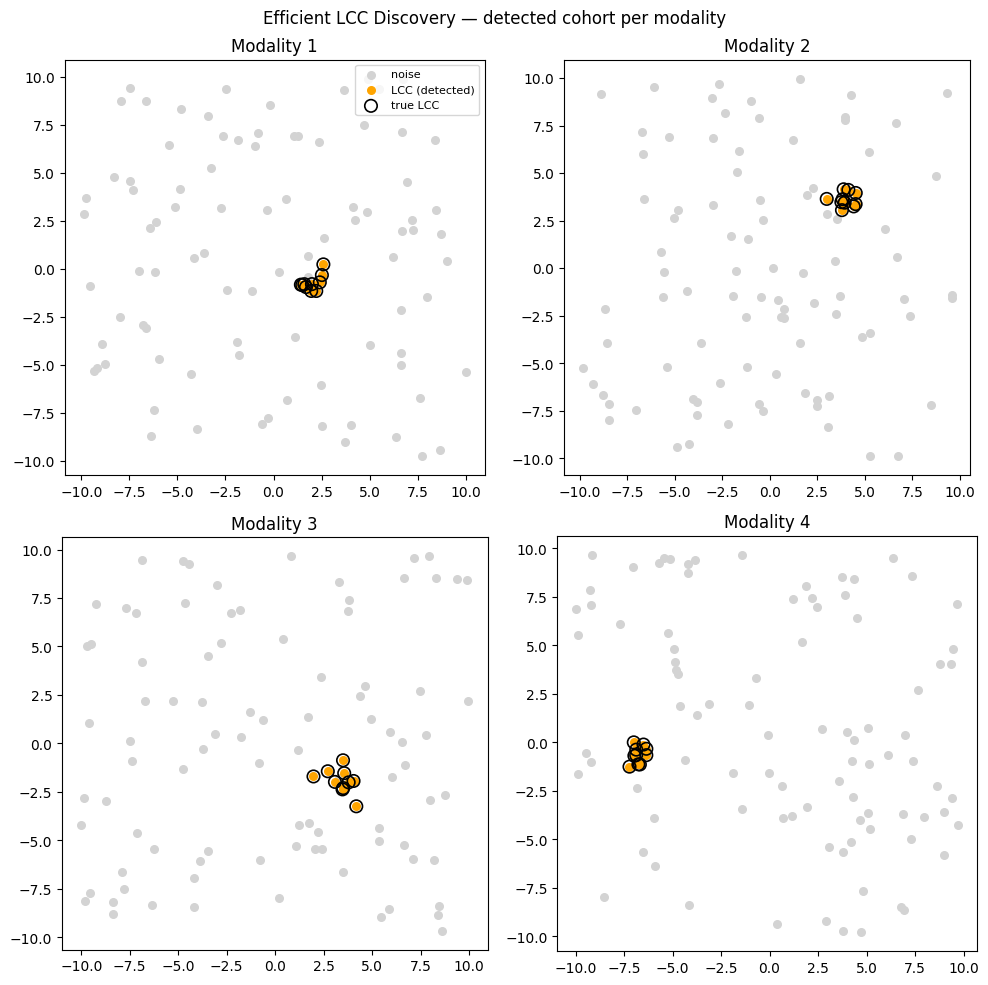

In [5]:
#visualisation of results
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for k, ax in enumerate(axes.flat):
    coords = coords_per_modality[k]
    is_detected = np.array([i in detected for i in range(n)])
    is_true = np.zeros(n, dtype=bool)
    is_true[true_cohort] = True

    ax.scatter(coords[~is_detected, 0], coords[~is_detected, 1],
               c="lightgray", label="noise", s=30)
    ax.scatter(coords[is_detected, 0], coords[is_detected, 1],
               c="orange", label="LCC (detected)", s=30)
    ax.scatter(coords[is_true, 0], coords[is_true, 1],
               facecolors="none", edgecolors="black", linewidths=1.2,
               label="true LCC", s=80)
    ax.set_title(f"Modality {k + 1}")
    ax.set_aspect("equal")

axes.flat[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Efficient LCC Discovery — detected cohort per modality")
fig.tight_layout()
plt.show()